<a href="https://colab.research.google.com/github/kuba11g/Eksploracja_Danych/blob/main/zad5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Eksploracyjna analiza danych - ceny domów w Ames (Iowa)

**Dane:** Kaggle, *House Prices - Advanced Regression Techniques* (zbiór Ames Housing, D. De Cock 2011), plik `train.csv`: 1460 transakcji z lat 2006-2010, 81 kolumn.

**Cel:** poznać dane przed budową modelu wyceny: typy zmiennych, braki, rozkład ceny, wartości odstające i to, co wpływa na cenę domu.

**Pytania naprowadzające:**
- Jaka jest zmienna docelowa? -> `SalePrice`, czyli cena sprzedaży domu w USD.
- Jakie rodzaje zmiennych są w zbiorze? -> liczbowe (powierzchnie, lata, liczby pomieszczeń), porządkowe (np. `OverallQual` 1-10, oceny `Ex/Gd/TA/Fa/Po`) i nominalne (dzielnica, typ budynku). Zmiennych czysto tekstowych (opisów) nie ma.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (8, 4.5), "font.size": 11})
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

df = pd.read_csv("train.csv")
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Typy danych

In [2]:
print(df.dtypes.value_counts(), "\n")

liczbowe = df.select_dtypes(include="number").columns.drop(["Id", "SalePrice"])
kategoryczne = df.select_dtypes(exclude="number").columns
print(f"Zmienne liczbowe: {len(liczbowe)}, kategoryczne (tekstowe): {len(kategoryczne)}\n")
print("Liczbowe:", list(liczbowe), "\n")
print("Kategoryczne:", list(kategoryczne), "\n")

print("MSSubClass (kod typu budynku):", sorted(df["MSSubClass"].unique()))
print("OverallQual (skala 1-10):", sorted(df["OverallQual"].unique()))

object     43
int64      35
float64     3
Name: count, dtype: int64 

Zmienne liczbowe: 36, kategoryczne (tekstowe): 43

Liczbowe: ['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold'] 

Kategoryczne: ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'He

**Wnioski:** 36 kolumn liczbowych (bez `Id` i `SalePrice`) i 43 tekstowe (kategoryczne). Nie wszystko, co liczbowe, jest naprawdę liczbą: `MSSubClass` to kod typu budynku (20, 30, ..., 190), czyli zmienna nominalna, a `OverallQual` i `OverallCond` to skale porządkowe 1-10. Z kolei wiele kolumn tekstowych jest porządkowych (`ExterQual`, `KitchenQual`, `BsmtQual`... ze skalą Ex > Gd > TA > Fa > Po). Powierzchnie są w **stopach kwadratowych** (1 stopa² ≈ 0,093 m²), a ceny w USD.

## 2. Statystyki opisowe

In [3]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.5,421.6,1.0,365.8,730.5,1095.2,1460.0
MSSubClass,1460.0,56.9,42.3,20.0,20.0,50.0,70.0,190.0
LotFrontage,1201.0,70.0,24.3,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,10516.8,9981.3,1300.0,7553.5,9478.5,11601.5,215245.0
OverallQual,1460.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
OverallCond,1460.0,5.6,1.1,1.0,5.0,5.0,6.0,9.0
YearBuilt,1460.0,1971.3,30.2,1872.0,1954.0,1973.0,2000.0,2010.0
YearRemodAdd,1460.0,1984.9,20.6,1950.0,1967.0,1994.0,2004.0,2010.0
MasVnrArea,1452.0,103.7,181.1,0.0,0.0,0.0,166.0,1600.0
BsmtFinSF1,1460.0,443.6,456.1,0.0,0.0,383.5,712.2,5644.0


In [4]:
df.describe(exclude="number").T

,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


**Wnioski:** domy budowano w latach 1872-2010, sprzedawano w latach 2006-2010. Wiele kolumn ma medianę 0 (`PoolArea`, `MiscVal`, `3SsnPorch`, `ScreenPorch`...), bo większość domów po prostu nie ma basenu czy werandy. W kolumnach kategorycznych niektóre cechy prawie się nie różnicują: `Utilities` ma `AllPub` w 1459 z 1460 domów, `Street` to w 1454 przypadkach `Pave`. Takie kolumny niewiele wniosą do modelu.

## 3. Braki danych - i co oznaczają

,liczba,odsetek [%]
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


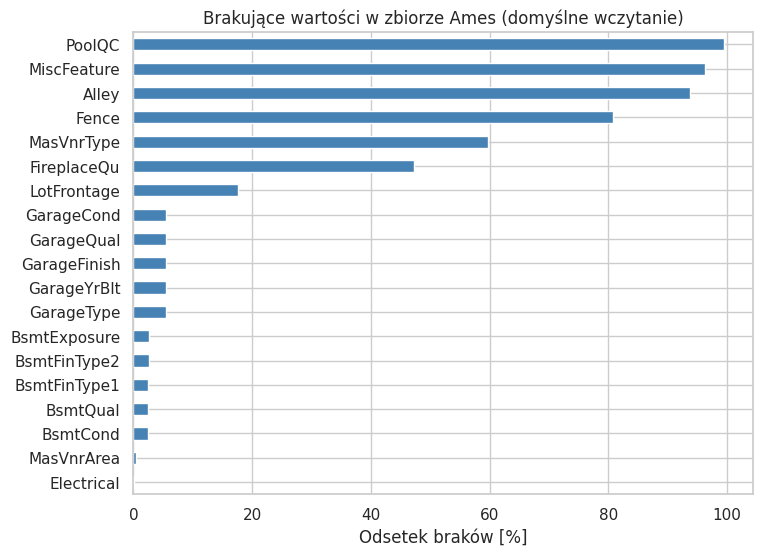

In [5]:
braki = pd.DataFrame({
    "liczba": df.isna().sum(),
    "odsetek [%]": (df.isna().mean() * 100).round(1),
})
braki = braki[braki["liczba"] > 0].sort_values("liczba", ascending=False)
display(braki)

ax = braki["odsetek [%]"].sort_values().plot.barh(figsize=(8, 6), color="steelblue")
ax.set_xlabel("Odsetek braków [%]")
ax.set_title("Brakujące wartości w zbiorze Ames (domyślne wczytanie)")
plt.show()

Pandas zgłasza 19 kolumn z brakami, ale według `data_description.txt` **NA w większości z nich nie oznacza braku danych, tylko brak danej cechy**:
- `PoolQC` -> brak basenu, `Alley` -> brak alejki, `Fence` -> brak ogrodzenia, `MiscFeature` -> brak dodatków, `FireplaceQu` -> brak kominka,
- `Garage*` (81 domów) -> brak garażu, `Bsmt*` (37 domów) -> brak piwnicy.

Jest jeszcze jedna pułapka: `MasVnrType` ma 872 "braki", a w opisie danych `None` to normalna kategoria ("brak okładziny"). Pandas domyślnie zamienia napis `"None"` na NaN. Sprawdźmy surowe wartości:

In [6]:
surowy = pd.read_csv("train.csv", keep_default_na=False)
surowy["MasVnrType"].value_counts()

,count
MasVnrType,
None,864
BrkFace,445
Stone,128
BrkCmn,15
NA,8


Faktycznie: 864 domy mają `None` (brak okładziny), a tylko 8 ma prawdziwe `NA`. Wczytujemy więc dane ponownie, tak żeby za brak uznawać tylko napis `NA`. Potem tam, gdzie NA znaczy "brak cechy", wpisujemy kategorię `"Brak"`. Dla piwnicy i garażu robimy to tylko w domach, które rzeczywiście ich nie mają (powierzchnia = 0), bo w dwóch domach z piwnicą brakuje pojedynczych opisów i to są prawdziwe braki.

In [7]:
df = pd.read_csv("train.csv", keep_default_na=False, na_values=["NA"])
print("MasVnrType:", df["MasVnrType"].value_counts(dropna=False).to_dict())

bez_piwnicy = df["TotalBsmtSF"] == 0
bez_garazu = df["GarageArea"] == 0
print("Domów bez piwnicy:", bez_piwnicy.sum(), "| bez garażu:", bez_garazu.sum())

for kol in ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]:
    df.loc[bez_piwnicy, kol] = "Brak"
for kol in ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]:
    df.loc[bez_garazu, kol] = "Brak"
for kol in ["Alley", "FireplaceQu", "PoolQC", "Fence", "MiscFeature"]:
    df[kol] = df[kol].fillna("Brak")

pozostale = df.isna().sum()
pozostale[pozostale > 0].sort_values(ascending=False)

MasVnrType: {'None': 864, 'BrkFace': 445, 'Stone': 128, 'BrkCmn': 15, nan: 8}
Domów bez piwnicy: 37 | bez garażu: 81


,0
LotFrontage,259
GarageYrBlt,81
MasVnrType,8
MasVnrArea,8
BsmtExposure,1
BsmtFinType2,1
Electrical,1


**Prawdziwych braków zostaje niewiele:**

| Kolumna | Braki | Co oznaczają |
|---|---|---|
| `LotFrontage` | 259 (17,7%) | prawdziwy brak (długość frontu działki); do uzupełnienia np. medianą w dzielnicy |
| `GarageYrBlt` | 81 | dom nie ma garażu, więc nie ma roku budowy garażu; nie uzupełniamy średnią |
| `MasVnrType`, `MasVnrArea` | 8 | prawdziwy brak (te same domy) |
| `BsmtExposure`, `BsmtFinType2` | po 1 | dom ma piwnicę, ale brakuje opisu: prawdziwy brak |
| `Electrical` | 1 | prawdziwy brak; można wstawić dominantę (`SBrkr`) |

Gdybyśmy na ślepo zrobili `dropna()` na danych wczytanych domyślnie, nie zostałby **ani jeden dom**: każdy wiersz ma jakieś NA (np. 1453 z 1460 domów nie ma basenu, więc ma "brak" w `PoolQC`).

## 4. Zmienna docelowa: `SalePrice`

In [8]:
cena = df["SalePrice"]
q1, q3 = cena.quantile([0.25, 0.75])
iqr = q3 - q1

pd.Series({
    "min": cena.min(), "Q1": q1, "mediana": cena.median(), "średnia": cena.mean(),
    "Q3": q3, "max": cena.max(), "IQR": iqr, "odch. std.": cena.std(),
    "skośność": cena.skew(),
}).round(2)

,0
min,34900.00
Q1,129975.00
mediana,163000.00
średnia,180921.20
Q3,214000.00
max,755000.00
IQR,84025.00
odch. std.,79442.50
skośność,1.88


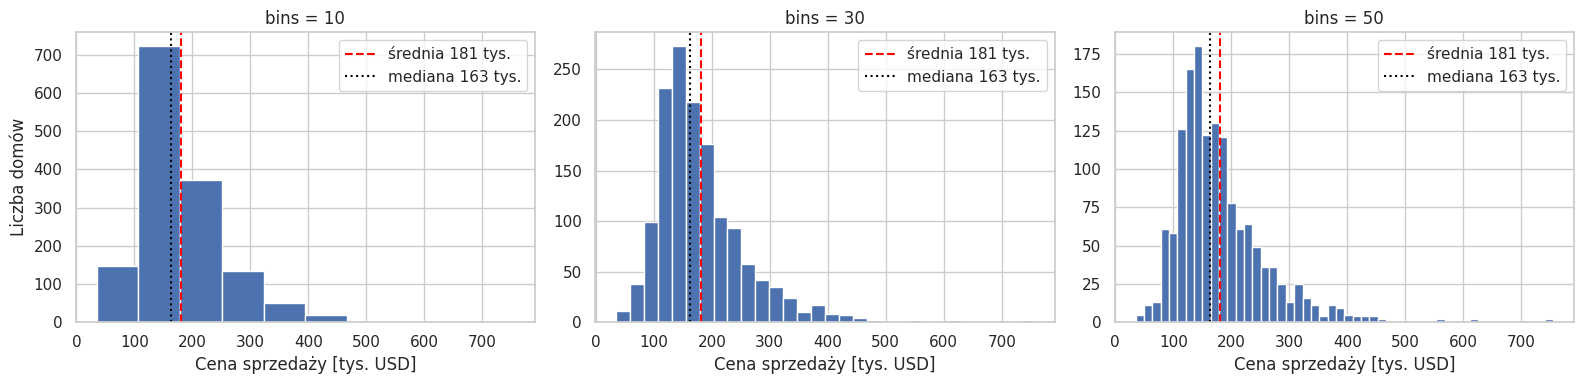

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, b in zip(axes, [10, 30, 50]):
    ax.hist(cena / 1000, bins=b, edgecolor="white")
    ax.axvline(cena.mean() / 1000, color="red", linestyle="--", label=f"średnia {cena.mean()/1000:.0f} tys.")
    ax.axvline(cena.median() / 1000, color="black", linestyle=":", label=f"mediana {cena.median()/1000:.0f} tys.")
    ax.set_title(f"bins = {b}")
    ax.set_xlabel("Cena sprzedaży [tys. USD]")
    ax.legend()
axes[0].set_ylabel("Liczba domów")
plt.tight_layout()
plt.show()

Górny płot: 340,038 USD -> domów powyżej: 61
Dolny płot: 3,938 USD -> domów poniżej: 0

Mediana OverallQual drogich domów: 9.0 | w całym zbiorze: 6.0
Mediana GrLivArea drogich domów: 2364.0 | w całym zbiorze: 1464.0

Dzielnice drogich domów:
 Neighborhood
NridgHt    27
NoRidge    11
StoneBr     9
Crawfor     3
Timber      3
Name: count, dtype: int64


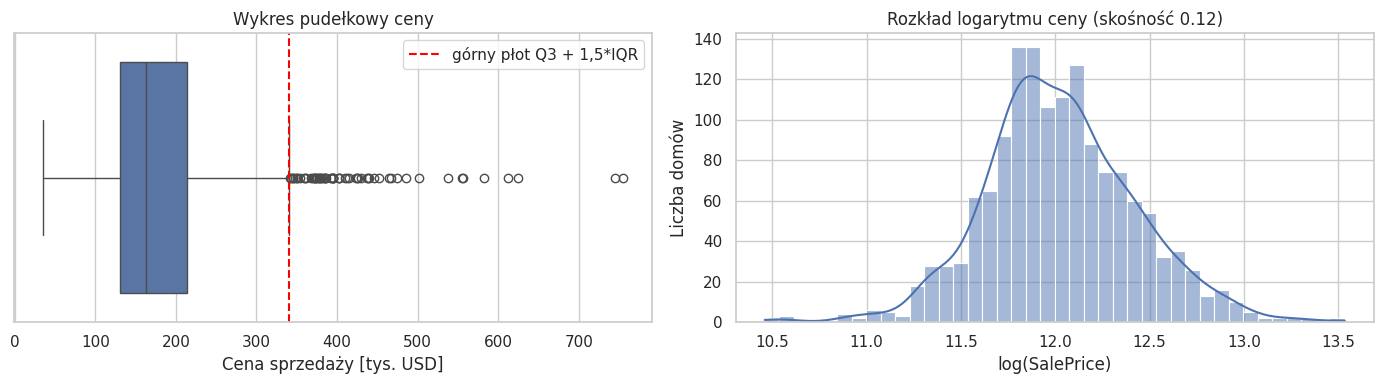

In [10]:
gorny_plot = q3 + 1.5 * iqr
odstajace = df[cena > gorny_plot]
print(f"Górny płot: {gorny_plot:,.0f} USD -> domów powyżej: {len(odstajace)}")
print(f"Dolny płot: {q1 - 1.5 * iqr:,.0f} USD -> domów poniżej: {(cena < q1 - 1.5 * iqr).sum()}\n")
print("Mediana OverallQual drogich domów:", odstajace["OverallQual"].median(),
      "| w całym zbiorze:", df["OverallQual"].median())
print("Mediana GrLivArea drogich domów:", odstajace["GrLivArea"].median(),
      "| w całym zbiorze:", df["GrLivArea"].median())
print("\nDzielnice drogich domów:\n", odstajace["Neighborhood"].value_counts().head(5))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=cena / 1000, ax=axes[0])
axes[0].axvline(gorny_plot / 1000, color="red", linestyle="--", label="górny płot Q3 + 1,5*IQR")
axes[0].set_xlabel("Cena sprzedaży [tys. USD]")
axes[0].set_title("Wykres pudełkowy ceny")
axes[0].legend()

sns.histplot(np.log(cena), bins=40, kde=True, ax=axes[1])
axes[1].set_xlabel("log(SalePrice)")
axes[1].set_ylabel("Liczba domów")
axes[1].set_title(f"Rozkład logarytmu ceny (skośność {np.log(cena).skew():.2f})")
plt.tight_layout()
plt.show()

**Wnioski o cenie:**
- Ceny wynoszą od 34 900 do 755 000 USD. Q1 = 129 975, mediana = 163 000, Q3 = 214 000, IQR = 84 025 USD.
- **Średnia (180 921) > mediana (163 000)**: rozkład jest **prawostronnie skośny** (skośność 1,88). Średnią ciągnie w górę "ogon" drogich domów. Przy `bins = 10` widać tylko ogólny kształt, przy 30 i 50 wyraźnie widać długi prawy ogon i pojedyncze domy powyżej 600 tys.
- Rozkład **nie jest normalny**, bo nie jest symetryczny. Po logarytmowaniu robi się prawie symetryczny (skośność 0,12), co przyda się przy modelu regresji.
- Wykres pudełkowy pokazuje **61 domów powyżej górnego płotu** (340 038 USD) i żadnego poniżej dolnego. To nie są błędy: to duże domy najwyższej jakości (mediana `OverallQual` 9 wobec 6 w całym zbiorze), głównie z najdroższych dzielnic (NridgHt, NoRidge, StoneBr). "Odstające" nie znaczy "do usunięcia".

## 5. Cena a jakość i lokalizacja (wykresy pudełkowe)

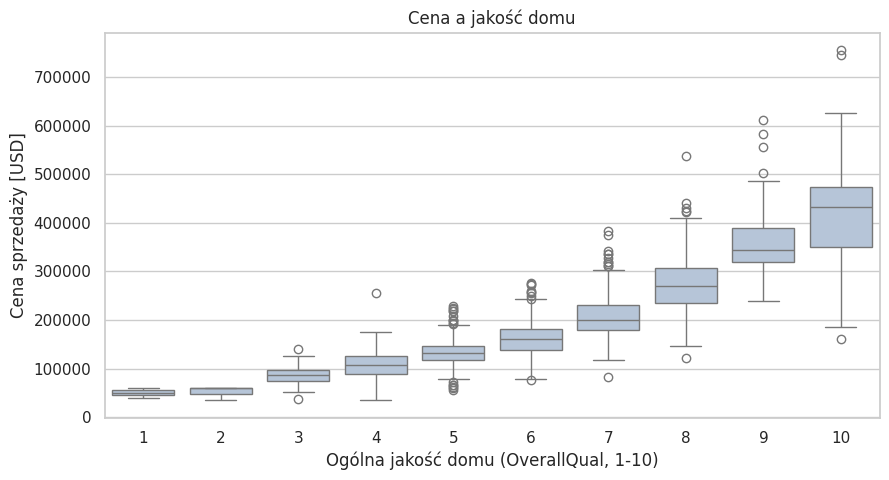

,count,median
OverallQual,,
1,2,50150.0
2,3,60000.0
3,20,86250.0
4,116,108000.0
5,397,133000.0
6,374,160000.0
7,319,200141.0
8,168,269750.0
9,43,345000.0


,Id,SalePrice,GrLivArea,SaleCondition,Neighborhood
523,524,184750,4676,Partial,Edwards
1298,1299,160000,5642,Partial,Edwards


In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=ax, color="lightsteelblue")
ax.set_xlabel("Ogólna jakość domu (OverallQual, 1-10)")
ax.set_ylabel("Cena sprzedaży [USD]")
ax.set_title("Cena a jakość domu")
plt.show()

display(df.groupby("OverallQual")["SalePrice"].agg(["count", "median"]).round(0))
df[(df["OverallQual"] == 10) & (df["SalePrice"] < 200_000)][
    ["Id", "SalePrice", "GrLivArea", "SaleCondition", "Neighborhood"]]

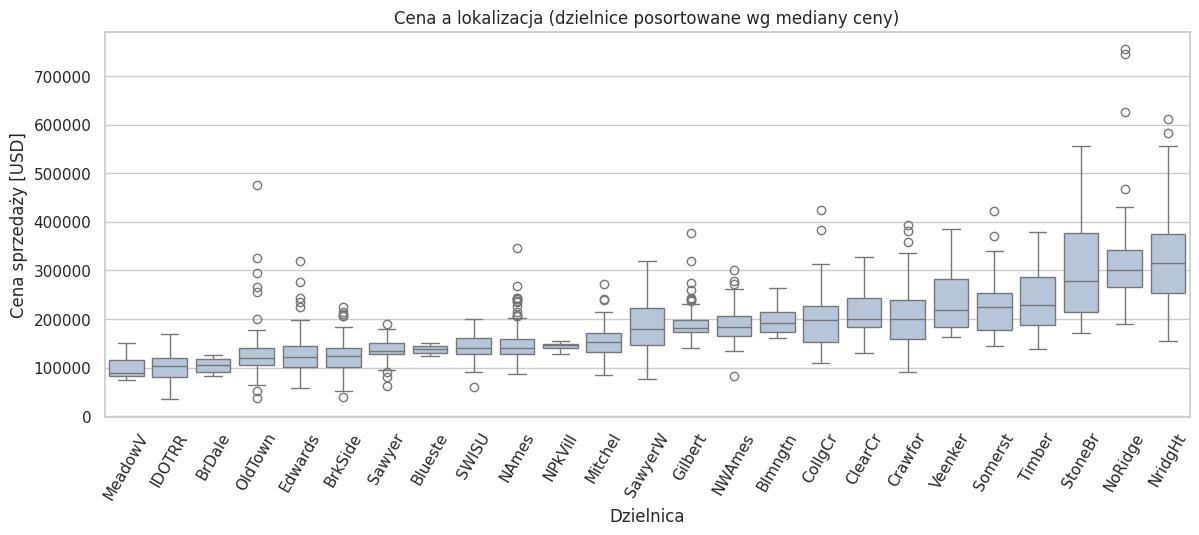

In [12]:
kolejnosc = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=kolejnosc, ax=ax, color="lightsteelblue")
ax.set_xlabel("Dzielnica")
ax.set_ylabel("Cena sprzedaży [USD]")
ax.set_title("Cena a lokalizacja (dzielnice posortowane wg mediany ceny)")
ax.tick_params(axis="x", rotation=60)
plt.show()

**Wnioski:** cena rośnie wyraźnie i niemal monotonicznie z jakością: mediana od ok. 50 tys. (jakość 1) przez 133 tys. (5) do 432 tys. USD (10). Dwa domy z oceną 10 sprzedano jednak poniżej 200 tys. (Id 524 i 1299). To dwa największe domy w zbiorze (4676 i 5642 stóp²), oba z `SaleCondition = Partial` (sprzedaż częściowa, niedokończona budowa), więc cena nie odzwierciedla wartości rynkowej. Lokalizacja też ma ogromne znaczenie: mediana ceny w najtańszej dzielnicy (MeadowV, 88 tys.) jest ponad 3,5 razy niższa niż w najdroższej (NridgHt, 315 tys.).

## 6. Zmienna kategoryczna: instalacja elektryczna (wykres słupkowy)

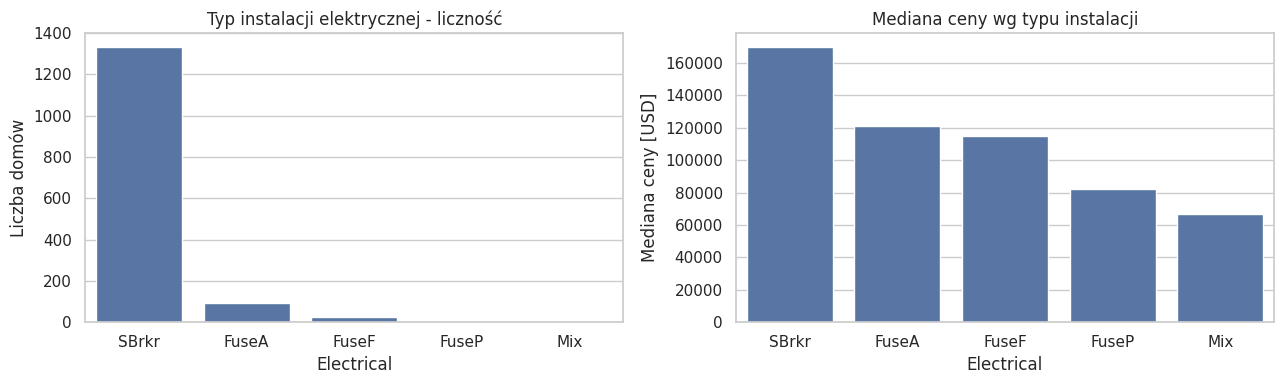

,count,median
Electrical,,
SBrkr,1334,170000.0
FuseA,94,121250.0
FuseF,27,115000.0
FuseP,3,82000.0
Mix,1,67000.0


In [13]:
kolejnosc_el = df["Electrical"].value_counts().index

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="Electrical", order=kolejnosc_el, ax=axes[0])
axes[0].set_title("Typ instalacji elektrycznej - liczność")
axes[0].set_ylabel("Liczba domów")

sns.barplot(data=df, x="Electrical", y="SalePrice", order=kolejnosc_el,
            estimator="median", errorbar=None, ax=axes[1])
axes[1].set_title("Mediana ceny wg typu instalacji")
axes[1].set_ylabel("Mediana ceny [USD]")
plt.tight_layout()
plt.show()

df.groupby("Electrical")["SalePrice"].agg(["count", "median"]).sort_values("count", ascending=False)

**Wnioski:** 1334 z 1459 domów (91%) ma nowoczesne wyłączniki (`SBrkr`), więc cecha słabo różnicuje domy. Rzadkie kategorie, czyli stare bezpieczniki (`FuseA`, `FuseF`, `FuseP`), wiążą się jednak z wyraźnie niższą ceną (mediana 121 tys., 115 tys. i 82 tys. wobec 170 tys.). To raczej sygnał starszego domu (mediana roku budowy: ok. 1940 przy bezpiecznikach wobec 1977 przy SBrkr) niż efekt samej instalacji. Przy `FuseP` (3 domy) i `Mix` (1 dom) mediana jest mało wiarygodna.

## 7. Sprzedaż w czasie (wykres liniowy)

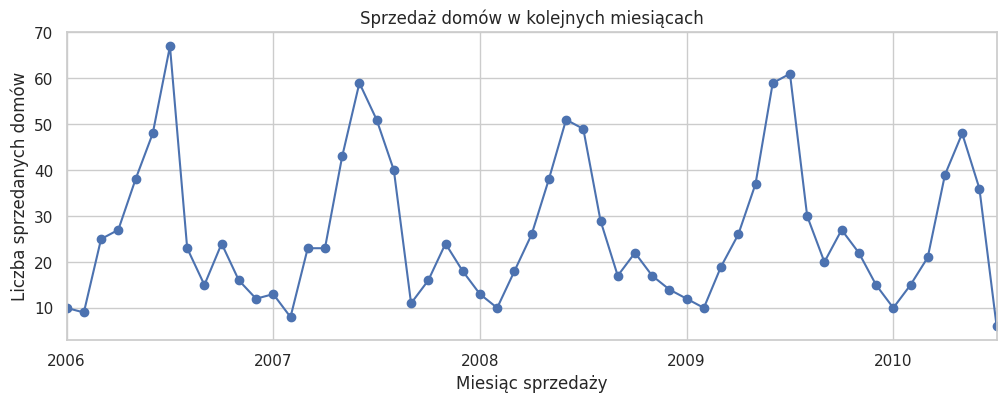

,liczba sprzedaży
MoSold,
1,58
2,52
3,106
4,141
5,204
6,253
7,234
8,122
9,63


In [14]:
sprzedaz = df.groupby(["YrSold", "MoSold"]).size()
sprzedaz.index = pd.to_datetime({
    "year": sprzedaz.index.get_level_values(0),
    "month": sprzedaz.index.get_level_values(1),
    "day": 1,
})

fig, ax = plt.subplots(figsize=(12, 4))
sprzedaz.plot(ax=ax, marker="o")
ax.set_xlabel("Miesiąc sprzedaży")
ax.set_ylabel("Liczba sprzedanych domów")
ax.set_title("Sprzedaż domów w kolejnych miesiącach")
plt.show()

df.groupby("MoSold").size().rename("liczba sprzedaży")

**Wnioski:** widać wyraźną **sezonowość**: co roku szczyt przypada na maj-lipiec (łącznie w czerwcu 253 transakcje, w lipcu 234), a dołek na zimę (styczeń 58, luty 52, grudzień 59). Spadek na samym końcu wykresu to koniec zbioru (dane kończą się w lipcu 2010), a nie trend rynkowy.

## 8. Co wpływa na cenę? Hipoteza: "większe domy są droższe"

In [15]:
kolumny_pow = [k for k in df.columns if "Area" in k or "SF" in k]
print("Kolumny z powierzchnią:", kolumny_pow, "\n")

korelacje_pow = (df[kolumny_pow + ["SalePrice"]].corr()["SalePrice"]
                 .drop("SalePrice").sort_values(ascending=False))
korelacje_pow.round(3).rename("korelacja z SalePrice")

Kolumny z powierzchnią: ['LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'PoolArea'] 



,korelacja z SalePrice
GrLivArea,0.709
GarageArea,0.623
TotalBsmtSF,0.614
1stFlrSF,0.606
MasVnrArea,0.477
BsmtFinSF1,0.386
WoodDeckSF,0.324
2ndFlrSF,0.319
OpenPorchSF,0.316
LotArea,0.264


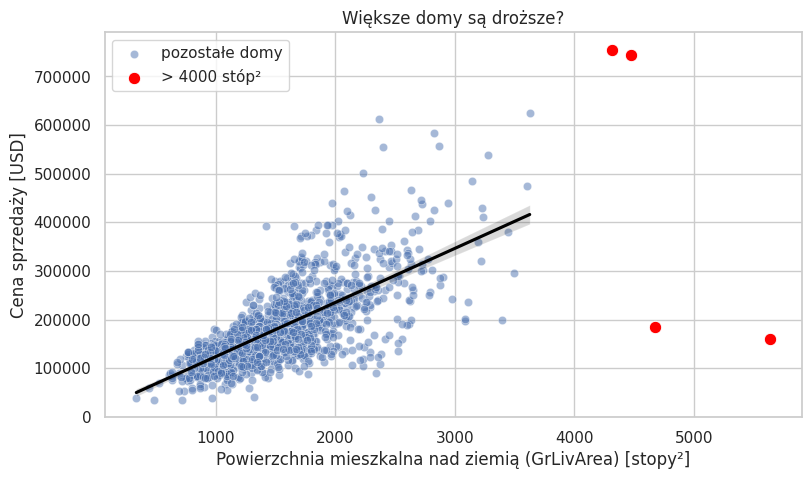

,Id,GrLivArea,SalePrice,OverallQual,SaleCondition,Neighborhood
523,524,4676,184750,10,Partial,Edwards
691,692,4316,755000,10,Normal,NoRidge
1182,1183,4476,745000,10,Abnorml,NoRidge
1298,1299,5642,160000,10,Partial,Edwards


Korelacja GrLivArea-SalePrice, wszystkie domy: 0.709
Korelacja bez domów > 4000 stóp²: 0.721


In [16]:
duze = df["GrLivArea"] > 4000

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df[~duze], x="GrLivArea", y="SalePrice", alpha=0.5, ax=ax, label="pozostałe domy")
sns.scatterplot(data=df[duze], x="GrLivArea", y="SalePrice", color="red", s=80, ax=ax, label="> 4000 stóp²")
sns.regplot(data=df[~duze], x="GrLivArea", y="SalePrice", scatter=False, color="black", ax=ax)
ax.set_xlabel("Powierzchnia mieszkalna nad ziemią (GrLivArea) [stopy²]")
ax.set_ylabel("Cena sprzedaży [USD]")
ax.set_title("Większe domy są droższe?")
plt.show()

display(df.loc[duze, ["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition", "Neighborhood"]])
print("Korelacja GrLivArea-SalePrice, wszystkie domy:", round(df["GrLivArea"].corr(df["SalePrice"]), 3))
print("Korelacja bez domów > 4000 stóp²:",round(df.loc[~duze, "GrLivArea"].corr(df.loc[~duze, "SalePrice"]), 3))

**Wnioski:** zależność jest wyraźna i w przybliżeniu **liniowa** (r = 0,71), ale rozrzut rośnie razem z powierzchnią: wśród dużych domów ceny różnią się bardziej. Cztery domy mają ponad 4000 stóp². Dwa (Id 692 i 1183, NoRidge) są najdroższe w zbiorze i pasują do trendu. Dwa pozostałe (Id 524 i 1299, Edwards) są ogromne i tanie: to te same sprzedaże częściowe (`Partial`) z poprzedniej sekcji. Po wyłączeniu domów > 4000 stóp² korelacja rośnie do 0,72. Autor zbioru (De Cock) sam zaleca usunięcie domów powyżej 4000 stóp² przed modelowaniem. Uzasadnieniem jest nietypowy charakter tych transakcji, a nie samo to, że "odstają".

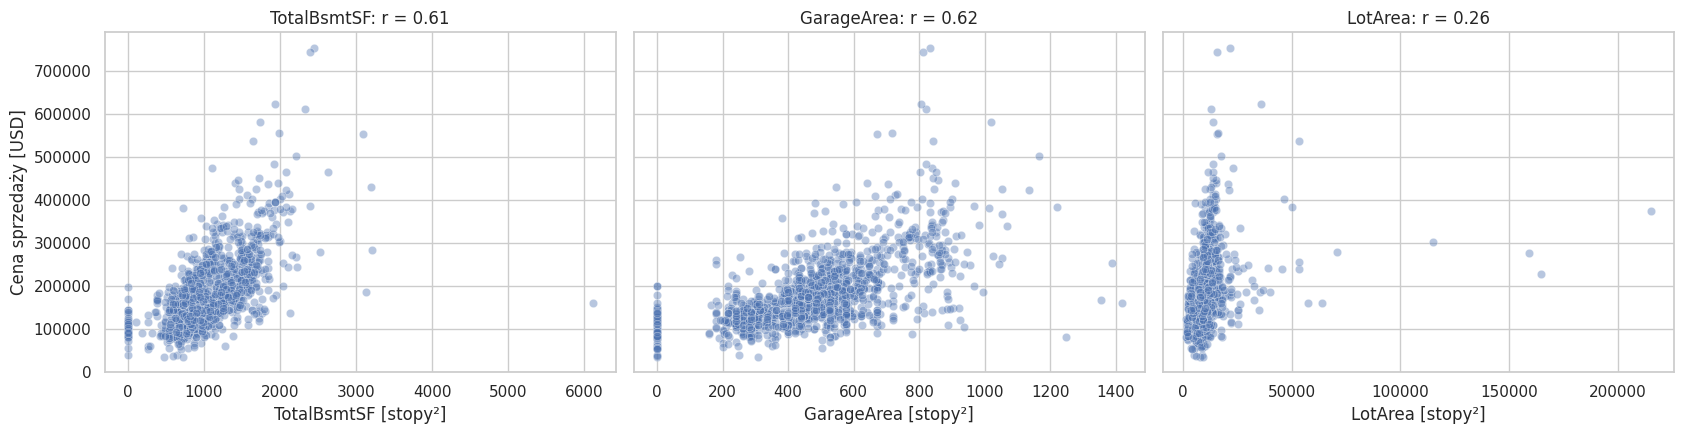

LotArea - korelacja Spearmana (odporna na wartości odstające): 0.456


In [17]:
porownanie = ["TotalBsmtSF", "GarageArea", "LotArea"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, kol in zip(axes, porownanie):
    sns.scatterplot(data=df, x=kol, y="SalePrice", alpha=0.4, ax=ax)
    ax.set_title(f"{kol}: r = {df[kol].corr(df['SalePrice']):.2f}")
    ax.set_xlabel(f"{kol} [stopy²]")
axes[0].set_ylabel("Cena sprzedaży [USD]")
plt.tight_layout()
plt.show()

print("LotArea - korelacja Spearmana (odporna na wartości odstające):",
      round(df["LotArea"].corr(df["SalePrice"], method="spearman"), 3))

**Wnioski:** spośród powierzchni najsilniej z ceną wiąże się powierzchnia mieszkalna `GrLivArea` (r = 0,71), potem powierzchnia garażu `GarageArea` (0,62) i piwnicy `TotalBsmtSF` (0,61). **Powierzchnia działki `LotArea` ma dużo słabszy związek (r = 0,26)**. Kilka ogromnych działek (do 215 tys. stóp²) kosztuje 160-540 tys. USD, czyli tyle co zwykłe dobre domy: cena nie rośnie proporcjonalnie do wielkości działki. Korelacja Spearmana dla `LotArea` wynosi 0,46, więc związek istnieje, ale Pearsona zaniżają skrajne wartości. Na wykresach `TotalBsmtSF` i `GarageArea` widać pionowy pasek przy 0: domy bez piwnicy lub garażu (te same, które miały NA w kolumnach opisowych).

## 9. Wiele zmiennych naraz: mapa korelacji

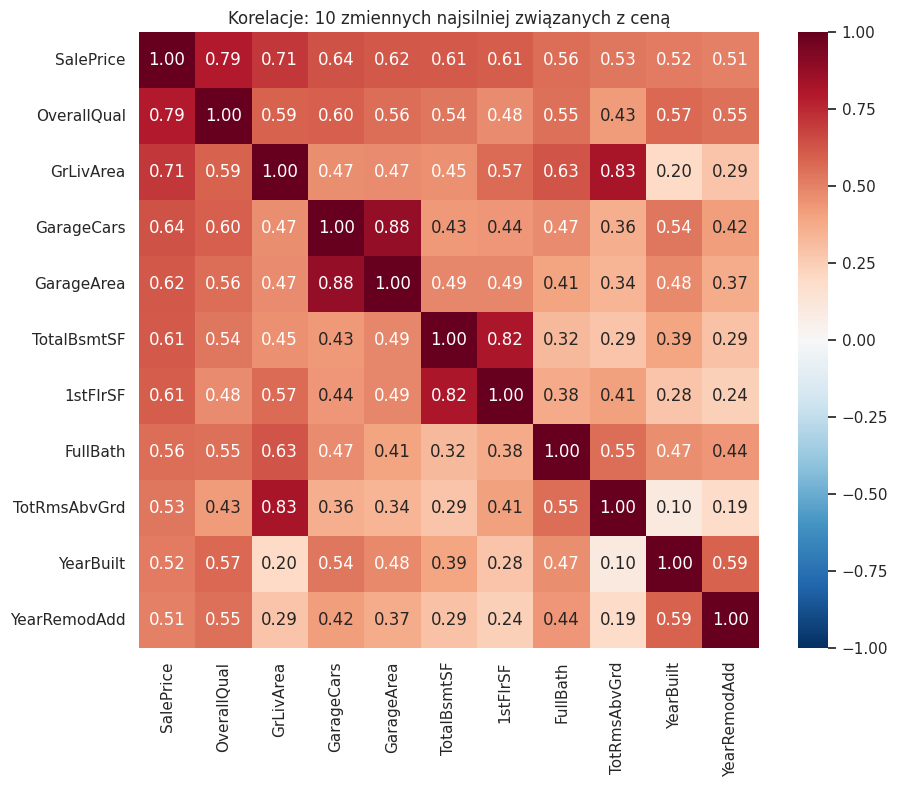

In [18]:
top = (df.select_dtypes("number").drop(columns="Id").corr()["SalePrice"]
       .abs().sort_values(ascending=False).head(11).index)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df[top].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Korelacje: 10 zmiennych najsilniej związanych z ceną")
plt.show()

**Wnioski:** najsilniej z ceną wiążą się `OverallQual` (0,79), `GrLivArea` (0,71), `GarageCars` (0,64), `GarageArea` (0,62), `TotalBsmtSF` i `1stFlrSF` (0,61), dalej liczba łazienek, liczba pokoi i rok budowy (ok. 0,5). Część tych zmiennych mówi prawie to samo: `GarageCars` i `GarageArea` (r = 0,88), `TotalBsmtSF` i `1stFlrSF` (0,82), `GrLivArea` i `TotRmsAbvGrd` (0,83). W modelu warto brać po jednej z każdej pary, żeby uniknąć współliniowości.

## 10. Podsumowanie

1. **Zmienna docelowa** `SalePrice` jest prawostronnie skośna (średnia 181 tys. > mediana 163 tys. USD). Logarytm ceny ma rozkład prawie symetryczny, co jest lepszym celem dla regresji.
2. **Braki danych** w większości nie są brakami: NA w `PoolQC`, `Alley`, `Fence`, `Garage*`, `Bsmt*` itd. oznacza brak danej cechy, a `"None"` w `MasVnrType` to kategoria, którą pandas domyślnie zamienia na NaN. Prawdziwych braków jest mało; najwięcej w `LotFrontage` (17,7%).
3. **Najważniejsze czynniki ceny:** ogólna jakość (`OverallQual`), powierzchnia mieszkalna (`GrLivArea`), garaż, piwnica i lokalizacja (różnica median między dzielnicami ponad 3,5x). Powierzchnia działki ma słaby wpływ.
4. **Hipoteza "większe domy są droższe" się potwierdza** (r = 0,71, zależność w przybliżeniu liniowa), z wyjątkiem dwóch ogromnych domów sprzedanych w transakcjach częściowych. Te warto usunąć przed modelowaniem, z uzasadnieniem.
5. **Odstające drogie domy** (61 powyżej górnego płotu) to prawdziwe, luksusowe nieruchomości, a nie błędy, więc zostają.
6. **Sezonowość:** najwięcej transakcji przypada na maj-lipiec.
7. **Zakres danych:** tylko domy (jedno- i dwurodzinne, szeregowce, bliźniaki) z jednego miasta w USA, bez mieszkań w blokach. Model zbudowany na tych danych nie przeniesie się wprost na polski rynek.